In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [30]:
custom_headers = [
    'age', 'workclass', 'fnlwgt', 'education', 'education-num', 
    'marital-status', 'occupation', 'relationship', 'race', 'sex', 
    'capital-gain', 'capital-loss', 'hours-per-week', 'native-country', 'income'
]
data=pd.read_csv("./dataset/adult.data", skipinitialspace=True, names=custom_headers, header=None)

In [8]:
data.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [17]:
print("Number of rows", len(data))
#class balance check
positive=data['income']=='<=50K'
print("Below threshold ratio:",np.mean(positive), "\nAbove Threshold ratio:", 1-np.mean(positive))


Number of rows 32561
Below threshold ratio: 0.7591904425539756 
Above Threshold ratio: 0.2408095574460244


In [ ]:
#missing Values
print("Following is the stat of missing values")
print((data.isna().any()).any())
print("No missing value here, so we will artificially generate")

Following is the stat of missing values
False
No missing value here, so we will artificially generate it


In [ ]:
data['income']=data['income'].transform(lambda x: int(x!='<=50K'))
data['sex']=data['sex'].transform(lambda x: int(x=='Male'))

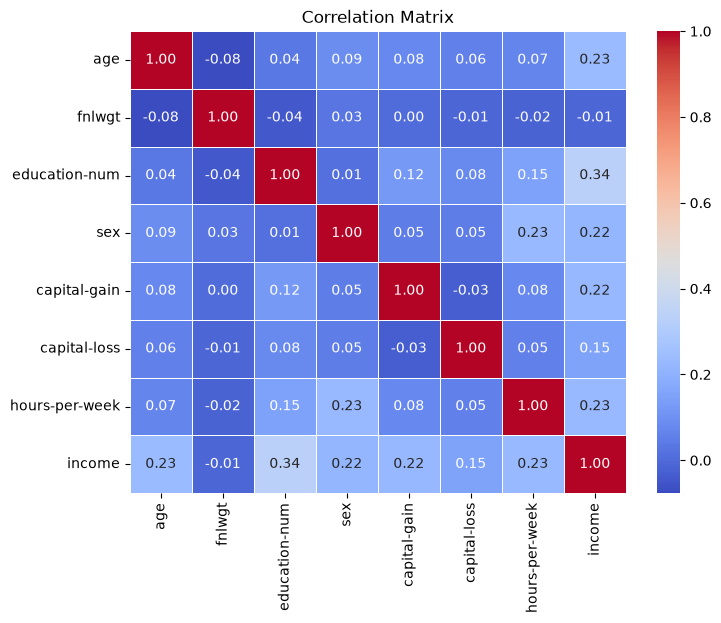

In [ ]:
numeric_data=data.select_dtypes(include=[np.number])
corr=numeric_data.corr()
# 3. Heatmap plot kiya
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Matrix')
plt.show()